# P07: the ResNet on small images (a control)

In P06 the pretrained ResNet reached 80.3% on validation, against about 59% for our best CNN (ADR 0010). But the two did not see the
same images: the ResNet worked at **224 px**, our CNNs at **64 px**. So the 20-point gain mixes two effects:

- **pretraining**: the ResNet starts from features learned on ImageNet;
- **resolution**: 224 px shows far more detail than 64 px.

To tell them apart, we give the *same* pretrained ResNet smaller images, with everything else unchanged (frozen network, new final
layer, same training):

| run | image size | what it tells us |
|---|---|---|
| `resnet18_head_64px` | 64 px | exactly the images the CNNs see. If it stays far above the CNN, pretraining is the main reason. |
| `resnet18_head_112px` | 112 px | a point in between, to see how the score moves with resolution. |
| `resnet18_head` (P06) | 224 px | the reference, not run again. |

Each of the two new runs uses 5 seeds (a few seconds each once the frozen features are computed). We also fine-tune the last block at
64 px (`layer4`), as in P06, to see whether it helps more on small images. **The test set (museum B) is not used here** (ADR 0003).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from deep_learning_project_waerniers_lamy.vision.utils import (
    build_resnet_head, load_resnet_data, load_result, run_experiment, summary)

BASE = {"model": "resnet18", "dropout": 0.0, "batch_size": 64, "weight_decay": 0.0, "seed": 0}
HEAD = {**BASE, "finetune": "head", "epochs": 30, "lr": 1e-3}  # frozen ResNet, new final layer (as in P06)
LAYER4 = {**BASE, "finetune": "layer4", "epochs": 8, "lr": 1e-4}  # last block also trained (as in P06)

runs_table = summary()


def saved_run(name):
    """The earliest saved run with this name."""
    rows = runs_table[runs_table["name"] == name].sort_values("date")
    return load_result(rows["file"].iloc[0])


head_224 = saved_run("resnet18_head")
cnn_longer = saved_run("cnn_longer")

# Safety check: the 224 px run of P06 used exactly this config, so only the image size differs below.
assert {**HEAD, "image_size": 224} == head_224["config"]

## 1. Frozen ResNet at 64 px

The very same 64 x 64 images as the CNNs (shrunk by the same function), standardised with the ImageNet mean and std. The last feature
map of the ResNet is then only 2 x 2.

In [2]:
head_64 = run_experiment("resnet18_head_64px", {**HEAD, "image_size": 64}, build_model=build_resnet_head,
                         load_fn=load_resnet_data, seeds=5)

2565 parameters | before training: loss 2.175 (ln 5 = 1.609), accuracy 17.3%
epoch   1 | train loss 0.902 acc 0.662 | val loss 1.032 acc 0.606
epoch   5 | train loss 0.607 acc 0.768 | val loss 0.826 acc 0.679
epoch  10 | train loss 0.507 acc 0.815 | val loss 0.828 acc 0.688
epoch  15 | train loss 0.446 acc 0.846 | val loss 0.847 acc 0.698
epoch  20 | train loss 0.403 acc 0.866 | val loss 0.876 acc 0.690
epoch  25 | train loss 0.374 acc 0.882 | val loss 0.911 acc 0.698
epoch  30 | train loss 0.344 acc 0.893 | val loss 0.921 acc 0.690

best validation accuracy 70.4% at epoch 18 (1 s)
seed 1 (1 of 4 more): training, about 1 s...
   best validation accuracy 69.6% at epoch 25
seed 2 (2 of 4 more): training, about 1 s...
   best validation accuracy 71.2% at epoch 18
seed 3 (3 of 4 more): training, about 1 s...
   best validation accuracy 69.6% at epoch 16
seed 4 (4 of 4 more): training, about 1 s...
   best validation accuracy 70.4% at epoch 23
saved results/resnet18_head_64px_2026-10-22_18-

## 2. Frozen ResNet at 112 px

In [3]:
head_112 = run_experiment("resnet18_head_112px", {**HEAD, "image_size": 112}, build_model=build_resnet_head,
                          load_fn=load_resnet_data, seeds=5)

2565 parameters | before training: loss 1.990 (ln 5 = 1.609), accuracy 16.0%
epoch   1 | train loss 0.839 acc 0.717 | val loss 0.908 acc 0.646
epoch   5 | train loss 0.513 acc 0.816 | val loss 0.661 acc 0.744
epoch  10 | train loss 0.421 acc 0.856 | val loss 0.652 acc 0.742
epoch  15 | train loss 0.373 acc 0.873 | val loss 0.672 acc 0.744
epoch  20 | train loss 0.322 acc 0.890 | val loss 0.683 acc 0.746
epoch  25 | train loss 0.297 acc 0.904 | val loss 0.705 acc 0.742
epoch  30 | train loss 0.273 acc 0.918 | val loss 0.718 acc 0.738

best validation accuracy 75.6% at epoch 12 (1 s)
seed 1 (1 of 4 more): training, about 1 s...
   best validation accuracy 75.6% at epoch 17
seed 2 (2 of 4 more): training, about 1 s...
   best validation accuracy 75.0% at epoch 16
seed 3 (3 of 4 more): training, about 1 s...
   best validation accuracy 75.8% at epoch 19
seed 4 (4 of 4 more): training, about 1 s...
   best validation accuracy 75.0% at epoch 15
saved results/resnet18_head_112px_2026-10-22_18

## 3. Last block also trained, at 64 px

As in P06 (stage 2), with one seed. On small images the last block works on a 4 x 4 map, so an epoch is much faster than at 224 px.

In [4]:
layer4_64 = run_experiment("resnet18_layer4_64px", {**LAYER4, "image_size": 64}, build_model=build_resnet_head,
                           load_fn=load_resnet_data, seeds=1)

8396293 parameters | before training: loss 2.175 (ln 5 = 1.609), accuracy 17.3%
epoch   1 | train loss 0.407 acc 0.878 | val loss 0.881 acc 0.665
epoch   5 | train loss 0.016 acc 1.000 | val loss 0.853 acc 0.706

best validation accuracy 70.8% at epoch 7 (130 s)
saved results/resnet18_layer4_64px_2026-10-22_18-17-57.pkl and added a row to results/experiments.csv


## 4. Validation accuracy against image size

The frozen ResNet at 64, 112 and 224 px (mean of 5 seeds, with the standard deviation as a bar), against the best CNN at 64 px and
the dense baseline.

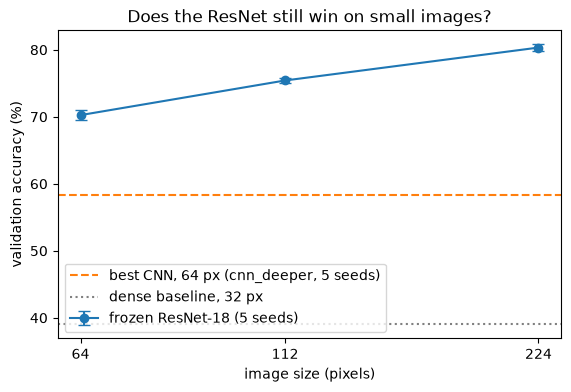

,size,mean (%),std (points)
0,64,70.2,0.7
1,112,75.4,0.4
2,224,80.3,0.5


In [5]:
table = summary()


def score(name):
    """Mean and std (in %) of the best validation accuracy over the 5 seeds of a run."""
    row = table[table["name"] == name].sort_values("date").iloc[0]
    return 100 * row["val_acc_mean"], 100 * row["val_acc_std"]


sizes = [64, 112, 224]
frozen = [score(name) for name in ["resnet18_head_64px", "resnet18_head_112px", "resnet18_head"]]
best_cnn = score("cnn_deeper_5seeds")
dense = score("dense_baseline")

plt.figure(figsize=(6.5, 4))
plt.errorbar(sizes, [m for m, s in frozen], yerr=[s for m, s in frozen], marker="o", capsize=4,
             label="frozen ResNet-18 (5 seeds)")
plt.axhline(best_cnn[0], linestyle="--", color="tab:orange", label="best CNN, 64 px (cnn_deeper, 5 seeds)")
plt.axhline(dense[0], linestyle=":", color="grey", label="dense baseline, 32 px")
plt.xscale("log")
plt.minorticks_off()
plt.xticks(sizes, [str(s) for s in sizes])
plt.xlabel("image size (pixels)")
plt.ylabel("validation accuracy (%)")
plt.title("Does the ResNet still win on small images?")
plt.legend()
plt.show()

pd.DataFrame({"size": sizes, "mean (%)": [round(m, 1) for m, s in frozen], "std (points)": [round(s, 1) for m, s in frozen]})

## 5. All the runs side by side

From `results/experiments.csv`. `n_params` counts the trainable weights.

In [6]:
names = ["dense_baseline", "cnn_first", "cnn_deeper_5seeds", "resnet18_head_64px", "resnet18_head_112px", "resnet18_head",
         "resnet18_layer4_64px", "resnet18_layer4"]
summary()[summary()["name"].isin(names)][
    ["name", "model", "image_size", "finetune", "n_params", "epochs", "best_val_acc", "val_acc_mean", "val_acc_std"]]

,name,model,image_size,finetune,n_params,epochs,best_val_acc,val_acc_mean,val_acc_std
8,resnet18_layer4,resnet18,224,layer4,8396293,8,0.8333,NaN,NaN
7,resnet18_head,resnet18,224,head,2565,30,0.8021,0.8033,0.0046
10,resnet18_head_112px,resnet18,112,head,2565,30,0.7562,0.7542,0.0039
11,resnet18_layer4_64px,resnet18,64,layer4,8396293,8,0.7083,NaN,NaN
9,resnet18_head_64px,resnet18,64,head,2565,30,0.7042,0.7025,0.0070
6,cnn_deeper_5seeds,cnn,64,NaN,98085,100,0.5896,0.5837,0.0112
1,cnn_first,cnn,64,NaN,23909,30,0.5375,0.5358,0.0079
0,dense_baseline,dense,32,NaN,393989,30,0.3854,0.3900,0.0090


## 6. Learning curves and smoother measures

The best epoch flatters a model (ADR 0008), so we also look at the last epoch, the mean of the last epochs and the score at the epoch
of lowest validation loss.

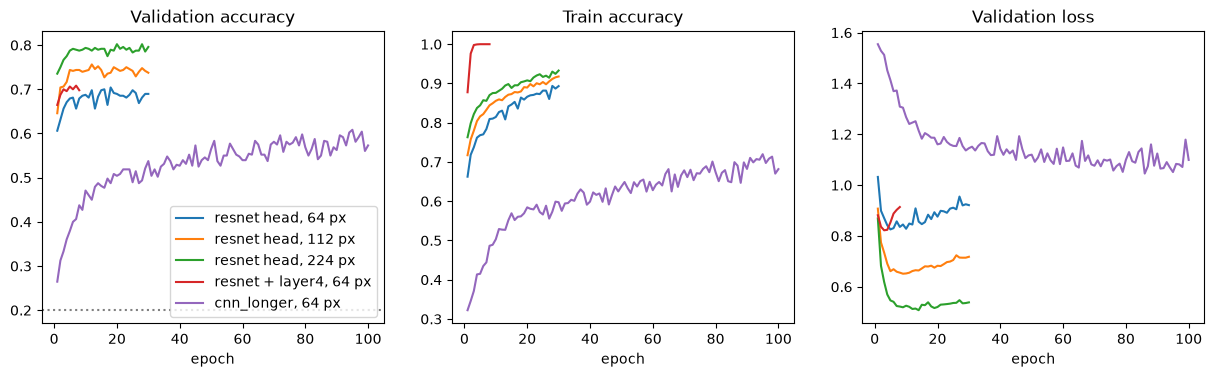

,"resnet head, 64 px","resnet head, 112 px","resnet head, 224 px","resnet + layer4, 64 px","cnn_longer, 64 px"
best epoch (%),70.4,75.6,80.2,70.8,60.8
last epoch (%),69.0,73.8,79.6,69.8,57.3
mean of last 10 (%),68.6,74.2,79.1,NaN,58.8
at lowest val loss (%),67.9,74.0,79.0,70.0,58.3
"train acc, last (%)",89.3,91.8,93.3,100.0,68.2
lowest val loss,0.8,0.7,0.5,0.8,1.0
mean of last 8 (%),NaN,NaN,NaN,69.5,NaN


In [7]:
histories = {
    "resnet head, 64 px": head_64["result"]["history"],
    "resnet head, 112 px": head_112["result"]["history"],
    "resnet head, 224 px": head_224["history"],
    "resnet + layer4, 64 px": layer4_64["result"]["history"],
    "cnn_longer, 64 px": cnn_longer["history"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for label, h in histories.items():
    epochs = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(epochs, h["val_acc"], label=label)
    axes[1].plot(epochs, h["train_acc"], label=label)
    axes[2].plot(epochs, h["val_loss"], label=label)
axes[0].set_title("Validation accuracy")
axes[1].set_title("Train accuracy")
axes[2].set_title("Validation loss")
axes[0].axhline(0.2, color="grey", linestyle=":")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend()
plt.show()


def measures(history):
    val = np.array(history["val_acc"])
    loss = np.array(history["val_loss"])
    last = min(10, len(val))
    return {
        "best epoch (%)": 100 * val.max(),
        "last epoch (%)": 100 * val[-1],
        f"mean of last {last} (%)": 100 * val[-last:].mean(),
        "at lowest val loss (%)": 100 * val[loss.argmin()],
        "train acc, last (%)": 100 * history["train_acc"][-1],
        "lowest val loss": loss.min(),
    }


pd.DataFrame({label: measures(h) for label, h in histories.items()}).round(1)

## 7. By genre, at the same image size

The CNN and the ResNet at 64 px, with the ResNet at 224 px for reference. Each genre has only 96 validation images.

In [8]:
confusions = {"cnn_longer (64 px)": cnn_longer["val_confusion"], "resnet head (64 px)": head_64["confusion"],
              "resnet head (224 px)": head_224["val_confusion"]}
pd.DataFrame({name: {genre: c.loc[genre, genre] / c.loc[genre].sum() for genre in c.index}
              for name, c in confusions.items()}).round(2)

,cnn_longer (64 px),resnet head (64 px),resnet head (224 px)
cityscape,0.65,0.76,0.76
landscape,0.61,0.65,0.80
portrait,0.61,0.71,0.80
religious_painting,0.59,0.57,0.72
still_life,0.57,0.83,0.93


## No test score here

This notebook is a control on validation. No model of this notebook is final, so none is scored on museum B (ADR 0003).

## What we see

Validation accuracy, best epoch. The frozen ResNet rows are the mean of 5 seeds, with the standard deviation.

| model | image size | validation accuracy |
|---|---|---|
| best CNN (`cnn_deeper`, 5 seeds) | 64 px | 58.4% (std 1.1) |
| frozen ResNet-18 | 64 px | **70.2%** (std 0.7) |
| frozen ResNet-18 | 112 px | **75.4%** (std 0.4) |
| frozen ResNet-18 | 224 px (P06) | **80.3%** (std 0.5) |
| ResNet-18 + last block trained | 64 px | 70.8% (one seed; 69.5% mean of its epochs) |

- **Pretraining matters, at equal resolution.** On the very same 64 x 64 images, the pretrained ResNet scores 70.2% against 58.4%
  for our best CNN: about 12 points more, far larger than the spread between seeds (0.7 to 1.1 points).
- **Resolution matters too.** For the ResNet, each doubling of the image size adds about 5 points (64 to 112 px: +5.2; 112 to 224 px:
  +4.9), again far above the seed spread (0.4 to 0.7). So of the 22 points between the ResNet of P06 (80.3%) and our best CNN
  (58.4%), roughly 12 come from pretraining and 10 from resolution. This is only approximate: it assumes our CNN would not gain from
  larger images, which we did not test (a CNN at 224 px would need a leaner data pipeline and about 30 minutes for 30 epochs).
- **Training the last block does not help on small images.** At 64 px it scores 70.8%, no different from the frozen 70.2%, and it
  reaches 100% train accuracy (overfitting). At 224 px it added 2 to 3 points (P06).
- **Resolution has a price.** The compute of the ResNet grows with the number of pixels: 112 px costs about a quarter, and 64 px about a
  twelfth, of what 224 px costs (estimated from the pixel counts, not measured). So 112 px gives 75.4% for about a quarter of the cost.
  Measuring the real cost per image on a CPU is the next step (P08).
- No test score here: none of these models is final (ADR 0003).